In [1]:
import sys
import os
import copy
import itertools
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

# 1. Thiết lập Project Root
PROJECT_ROOT = '/home/sonndt/Projects/FFV_PINN'
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from jaxpi.samplers import UniformSampler, MeshSampler
from nc_porous_1d.config import base_line_case_1
from nc_porous_1d.train import train_1d


def create_batches_1d(config):
    """
    Bộ sinh batch điểm nội miền cho bài toán 1 chiều.
    Tự động tính toán khoảng đệm biên (safety buffer) phụ thuộc vào stencil_reach của sơ đồ số.
    """
    L = config.physics.L
    scheme = getattr(config.diff, "scheme", "ad").lower().strip()

    if scheme in ["nd", "can", "ffv"]:
        n_x = getattr(config.diff, "n_x", 101)
        dx = L / (n_x - 1)

        # Cập nhật h_stencil đồng bộ chính xác với bước lưới
        config.diff.h_stencil = float(dx)

        # Stencil reach: CAN và FFV 1D cần h/2 hoặc h (1 bước), ND bậc cao có thể cần 2 bước
        stencil_reach = 1.0 if scheme in ["can", "ffv"] else 2.0

        use_continuous_mesh = getattr(config.diff, "use_continuous_mesh", False)

        if use_continuous_mesh:
            # Miền liên tục có đệm biên an toàn để các điểm stencil không văng ra ngoài [0, L]
            safe_x = stencil_reach * dx + 1e-5
            domain_safe = jnp.array([[safe_x, L - safe_x]])
            sampler = UniformSampler(domain_safe, config.training.batch_size)

        else:
            # Lưới rời rạc: loại bỏ đúng số nút sát biên theo stencil_reach
            num_exclude = int(stencil_reach)
            x_inner = jnp.linspace(
                num_exclude * dx, L - num_exclude * dx, n_x - 2 * num_exclude
            )
            # Reshape thành mảng (N, 1) chuẩn đầu vào cho MeshSampler
            mesh_points = x_inner.reshape(-1, 1)

            sampler = MeshSampler(
                mesh=mesh_points, batch_size=config.training.batch_size
            )

    elif scheme == "ad":
        # Vi phân tự động: lấy mẫu ngẫu nhiên trên toàn bộ miền (0, L)
        domain = jnp.array([[0.0, L]])
        sampler = UniformSampler(domain, config.training.batch_size)

    else:
        raise ValueError(f"Sơ đồ không hợp lệ: {scheme}")

    if config.training.random_sampling:
        return sampler
    return itertools.repeat(next(iter(sampler)))



def run_ablation_experiment_1d(exp_name, org_config_mod, modify_config_fn=None,pts=False,use_continuous_mesh=False):
    """
    Hàm chạy thí nghiệm Ablation Study tự động:
    Clone config sâu, áp dụng các tuỳ chỉnh, sinh batch và tiến hành huấn luyện.
    """
    sub_config = copy.deepcopy(org_config_mod.get_config())
    sub_config.wandb.name = f"{sub_config.wandb.name}_{exp_name}"

    if modify_config_fn is not None:
        sub_config = modify_config_fn(sub_config,pts=pts,use_continuous_mesh=use_continuous_mesh)

    batches = create_batches_1d(sub_config)
    
    # Huấn luyện mô hình 1D (hàm train_1d nhận trực tiếp config và samplers)
    model, history = train_1d(config=sub_config, sampler=batches)
    return model, history


In [2]:
experiments = {}

# 1. Thí nghiệm với Vi phân tự động thuần túy (AD)
def setup_ad(cfg,pts=False):
    cfg.diff.scheme = "ad"
    cfg.training.max_steps = 50000
    cfg.pseudo_time.enabled = pts
    return cfg

# 2. Thí nghiệm với Simplified FVM (FFV-PINN)
def setup_ffv(cfg, pts=False,use_continuous_mesh=False):
    cfg.diff.scheme = "ffv"
    cfg.diff.n_x = 101
    cfg.diff.use_continuous_mesh = use_continuous_mesh
    cfg.training.max_steps = 50000
    cfg.pseudo_time.enabled = pts
    return cfg

# 3. Thí nghiệm với Coupled Auto-Numerical Differentiation (CAN-PINN)
def setup_can(cfg, pts=False,use_continuous_mesh=False):
    cfg.diff.scheme = "can"
    cfg.diff.n_x = 101
    cfg.diff.use_continuous_mesh = False
    cfg.training.max_steps = 50000
    cfg.diff.use_continuous_mesh = use_continuous_mesh
    cfg.pseudo_time.enabled = pts
    return cfg

model_ffv_fix_grid, hist_ffv_fix_grid = run_ablation_experiment_1d("Scheme_can_pts_on", base_line_case_1, setup_can,pts=True,use_continuous_mesh=False)
#model_ffv_continuous_mesh, hist_ffv_continuous_mesh_ = run_ablation_experiment_1d("Scheme_FFV_continuous_mesh", base_line_case_1, setup_ffv,pts=True,use_continuous_mesh=True)
#model_ad, hist_ad = run_ablation_experiment_1d("Scheme_AD_pts_on", base_line_case_1, setup_ad,pts=True)
#model_ad, hist_ad_pts_on_ = run_ablation_experiment_1d("Scheme_AD_pts_on", base_line_case_1, setup_ad,pts=True)
#_, hist_ffv_pts_off_ = run_ablation_experiment_1d("Scheme_FFV_pts_off", base_line_case_1, setup_ffv,pts=False,c_bound=0.01)

# print("\n--- BẮT ĐẦU CHẠY ABLATION STUDY 1D ---")
# c_bound_list = [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0]
# hist_ffv_pts_on_results = {}
# for c_bound in c_bound_list:
#     _, hist_ffv_pts_on = run_ablation_experiment_1d(
#         f"Scheme_FFV_pts_on_c_bound_{c_bound}", base_line_case_1, setup_ffv, pts=True, c_bound=c_bound
#     )
#     hist_ffv_pts_on_results[c_bound] = hist_ffv_pts_on
# _, hist_ffv_pts_off = run_ablation_experiment_1d("Scheme_FFV_pts_off", base_line_case_1, setup_ffv)


Training 1D PINN:   0%|          | 0/50000 [00:00<?, ?it/s]

/home/sonndt/Projects/FFV_PINN/nc_porous_1d/train.py:68: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  axes[1, 0].set_yscale("log")


--> Đã lưu biểu đồ phân tích chẩn đoán tại: /home/sonndt/Projects/FFV_PINN/nc_porous_1d/outputs/1D_Conjugate_Conduction_Scheme_can_pts_on/diagnostic_stability.png
Hoàn thành! Sai số Relative L2 cuối cùng: 4.6539e-04


In [3]:
model_ffv_fix_grid, hist_ffv_fix_grid = run_ablation_experiment_1d("Scheme_FFV_pts_on", base_line_case_1, setup_ffv,pts=False,use_continuous_mesh=False)

Training 1D PINN:   0%|          | 0/50000 [00:00<?, ?it/s]

--> Đã lưu biểu đồ phân tích chẩn đoán tại: /home/sonndt/Projects/FFV_PINN/nc_porous_1d/outputs/1D_Conjugate_Conduction_Scheme_FFV_pts_on/diagnostic_stability.png
Hoàn thành! Sai số Relative L2 cuối cùng: 6.7572e-04


In [6]:
#print key of hist_ffv_pts_on_
hist_list = [hist_ffv_fix_grid, hist_ffv_continuous_mesh_, hist_ffv_fix_grid]
model_list = [model_ffv_fix_grid, model_ffv_continuous_mesh, model_ffv_fix_grid]
T_list = []
x_test = jnp.linspace(0.0, 1.0, 200) 
for model in model_list:
    T_pred = model.T_pred_fn(model.state.params,x_test)
    T_list.append(T_pred)
T_list.append(model_list[0].compute_analytical_solution(x_test))

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Thiết lập font và style chuẩn cho bài báo khoa học (Elsevier / ASME style)
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "mathtext.fontset": "cm",  # Computer Modern font cho công thức toán
    "figure.dpi": 300
})

def plot_comparison_1d(x_test, T_exact, T_pred_ad, T_pred_ffv, save_path="comparison_1d.png"):
    """
    Vẽ biểu đồ phân bố nhiệt độ so sánh giữa Nghiệm giải tích, PINN-AD và PINN-FFV.
    """
    fig, ax = plt.subplots(figsize=(6, 5))

    # 1. Đường màu đen: Nghiệm giải tích (Analytical)
    ax.plot(x_test, T_exact, 'k-', linewidth=1.5, label='Analytical', zorder=1)

    # Lấy mẫu thưa hơn một chút cho các marker để hình vẽ không bị đè nét đặc kín
    num_markers = 30
    indices = np.linspace(0, len(x_test) - 1, num_markers, dtype=int)
    x_sub = x_test[indices]
    T_ad_sub = T_pred_ad[indices]
    T_ffv_sub = T_pred_ffv[indices]

    # 2. Điểm màu đỏ hình tròn (o): PINN (FFV)
    # Dùng markeredgecolor màu đỏ, ruột rỗng (none) tương tự style của Fig. 3b trong bài báo
    ax.plot(x_sub, T_ffv_sub, 'o', color='red', markerfacecolor='none', 
            markeredgecolor='red', markeredgewidth=1.2, markersize=6.5, 
            label='PINN (FFV)', zorder=3)

    # 3. Điểm màu xanh nước biển hình hoa thị (*): PINN (AD)
    ax.plot(x_sub, T_ad_sub, '*', color='#1f77b4', markersize=8, 
            markeredgewidth=1.2, label='PINN (AD)', zorder=2)

    # Thiết lập giới hạn và định dạng các trục
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.02])
    ax.set_xlabel(r'$x/L$')
    ax.set_ylabel(r'$T$')

    # Định dạng vạch chia (ticks) hướng vào trong theo chuẩn Journal
    ax.tick_params(direction='in', top=True, right=True, length=5)
    ax.tick_params(which='minor', direction='in', top=True, right=True, length=2.5)
    ax.minorticks_on()

    # Chú thích góc trái dưới (Annotation thông số vật lý)
    ax.text(0.05, 0.15, r'$k_1/k_2 = 5$', transform=ax.transAxes, fontsize=12)

    # Legend đặt ở góc trên bên phải, không viền để thoáng hình
    ax.legend(frameon=False, loc='upper right')

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"--> Đã lưu biểu đồ thành công tại: {save_path}")

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Cấu hình style chuẩn Elsevier / ASME
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "mathtext.fontset": "cm",
    "figure.dpi": 300,
})


def plot_comparison_refined(
    x_test, T_exact, T_pred_ad, T_pred_ffv, save_path="comparison_1d_refined.png"
):
  fig, ax = plt.subplots(figsize=(6, 5))

  # 1. Đường màu đen nét liền: Nghiệm giải tích
  ax.plot(
      x_test,
      T_exact,
      "k-",
      linewidth=1.8,
      label="Analytical",
      zorder=1,
  )

  # Tạo chỉ số lấy mẫu thưa cho các điểm marker
  num_markers = 26
  indices = np.linspace(0, len(x_test) - 1, num_markers, dtype=int)
  x_sub = x_test[indices]
  T_ad_sub = T_pred_ad[indices]
  T_ffv_sub = T_pred_ffv[indices]

  # 2. Đường nét đứt màu đỏ kết hợp vòng tròn rỗng (o): PINN (FFV)
  # Vẽ đường nét đứt trên toàn bộ miền để thấy tính liên tục
#   ax.plot(
#       x_test,
#       T_pred_ffv,
#       color="#d62728",
#       linestyle="--",
#       linewidth=1.4,
#       alpha=0.85,
#       zorder=2,
#   )
  # Vẽ các điểm tròn rỗng thưa lên trên
  ax.plot(
      x_sub,
      T_ffv_sub,
      "o",
      markerfacecolor="none",
      markeredgecolor="#d62728",
      markeredgewidth=1.3,
      markersize=6.5,
      label="PINN (FFV)",
      zorder=3,
  )

  # 3. Ký hiệu hoa thị asterisk thanh mảnh (không phải ngôi sao dày): PINN (AD)
  # Có thể dùng '$\ast$' hoặc '+' hoặc 'x'. Ở đây dùng '$\ast$' chuẩn phong cách Elsevier
  ax.plot(
      x_sub,
      T_ad_sub,
      marker="$\\ast$",
      linestyle="None",
      color="#1f77b4",
      markersize=6.5,
      markeredgewidth=1.3,
      label="PINN (AD)",
      zorder=3,
  )

  # Tùy chỉnh trục và tỷ lệ
  ax.set_xlim([0.0, 1.0])
  ax.set_ylim([0.0, 1.02])
  ax.set_xlabel(r"$x/L$")
  ax.set_ylabel(r"$T$")

  ax.tick_params(direction="in", top=True, right=True, length=5)
  ax.tick_params(which="minor", direction="in", top=True, right=True, length=2.5)
  ax.minorticks_on()

  # Ghi chú thông số tỉ lệ độ dẫn nhiệt
  ax.text(0.06, 0.14, r"$k_1/k_2 = 5$", transform=ax.transAxes, fontsize=12)

  # Bảng chú giải
  ax.legend(frameon=False, loc="upper right")

  plt.tight_layout()
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
  plt.show()
  print(f"--> Đã lưu biểu đồ tinh chỉnh tại: {save_path}")

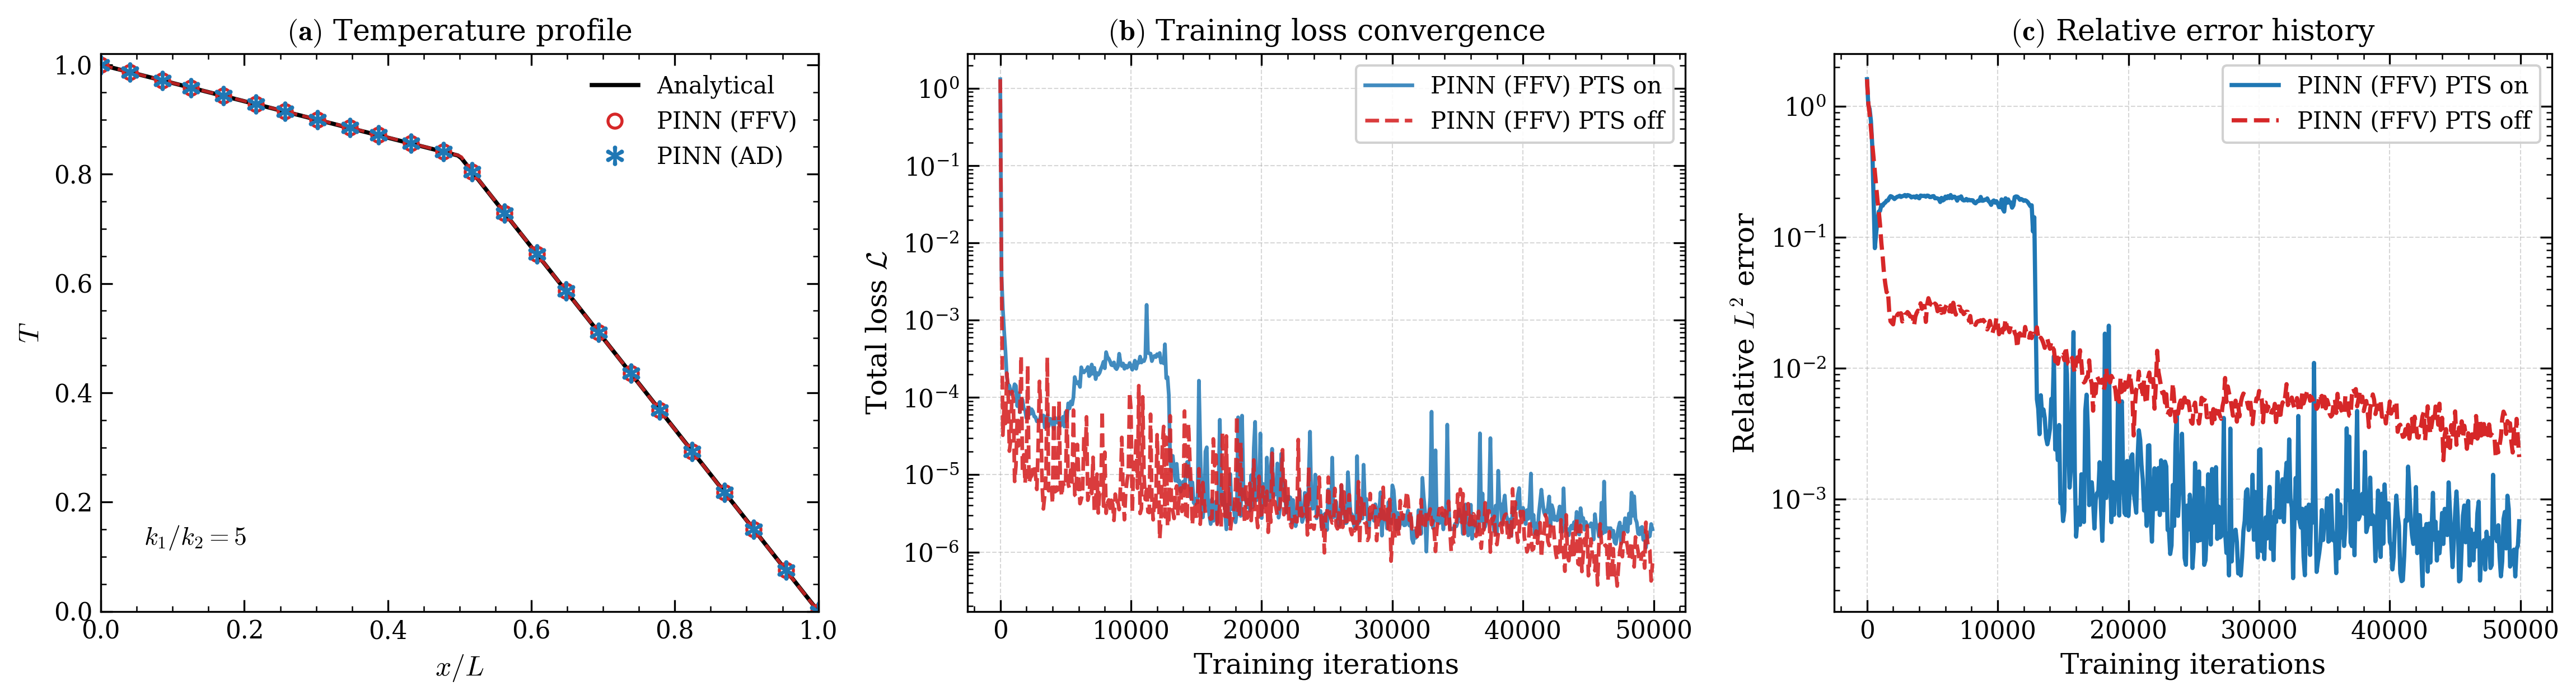

--> Đã lưu thành công biểu đồ 3 panel tại:
    - PNG: case1_combined_three_panels.png
    - PDF: case1_combined_three_panels.pdf


In [11]:
import os
import matplotlib.pyplot as plt
import numpy as np

# Thiết lập thông số đồ họa theo tiêu chuẩn tạp chí Elsevier (IJHMT, JCP, CMAME)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10,
    "figure.dpi": 300,
})


def plot_combined_case1_three_panels(
    x_eval,
    T_exact,
    T_pred_ad,
    T_pred_ffv,
    hist_ad,
    hist_ffv,
    log_freq=100,
    save_path="case1_combined_three_panels.png",
):
  """Vẽ khung hình 3 panel nằm ngang (1x3) cho Case 1D Conjugate Conduction."""
  fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))

  # Màu sắc và style đồng bộ xuyên suốt cả 3 đồ thị
  c_ana = "black"
  c_ad = "#1f77b4"  # Xanh dương
  c_ffv = "#d62728"  # Đỏ

  # =========================================================================
  # PANEL (a): NHIỆT ĐỘ T(x) SO VỚI GIẢI TÍCH
  # =========================================================================
  # 1. Đường giải tích màu đen nét liền
  axes[0].plot(
      x_eval, T_exact, color=c_ana, linestyle="-", linewidth=1.8, label="Analytical"
  )

  # Lấy mẫu thưa cho các marker để hình không bị rối
  num_markers = 24
  idx_sub = np.linspace(0, len(x_eval) - 1, num_markers, dtype=int)

  # 2. FFV: Nét đứt màu đỏ + điểm rỗng (o)
  axes[0].plot(
      x_eval, T_pred_ffv, color=c_ffv, linestyle="--", linewidth=1.4, alpha=0.85
  )
  axes[0].plot(
      x_eval[idx_sub],
      T_pred_ffv[idx_sub],
      "o",
      markerfacecolor="none",
      markeredgecolor=c_ffv,
      markeredgewidth=1.3,
      markersize=6,
      label="PINN (FFV)",
  )

  # 3. AD: Dấu hoa thị asterisk (*) xanh dương
  axes[0].plot(
      x_eval[idx_sub],
      T_pred_ad[idx_sub],
      marker="$\\ast$",
      linestyle="None",
      color=c_ad,
      markersize=8,
      markeredgewidth=0.8,
      label="PINN (AD)",
  )

  axes[0].set_xlim([0.0, 1.0])
  axes[0].set_ylim([0.0, 1.02])
  axes[0].set_xlabel(r"$x/L$")
  axes[0].set_ylabel(r"$T$")
  axes[0].set_title(r"$\mathbf{(a)}$ Temperature profile")
  axes[0].text(0.06, 0.12, r"$k_1/k_2 = 5$", transform=axes[0].transAxes)
  axes[0].legend(frameon=False, loc="upper right")

  # =========================================================================
  # PANEL (b): TRAINING LOSS CONVERGENCE
  # =========================================================================
  steps_ad = np.arange(len(hist_ad["loss"])) * log_freq
  steps_ffv = np.arange(len(hist_ffv["loss"])) * log_freq

  axes[1].plot(
      steps_ad,
      hist_ad["loss"],
      color=c_ad,
      linestyle="-",
      linewidth=1.6,
      alpha=0.85,
      label="PINN (FFV) PTS on",
  )
  axes[1].plot(
      steps_ffv,
      hist_ffv["loss"],
      color=c_ffv,
      linestyle="--",
      linewidth=1.6,
      alpha=0.9,
      label="PINN (FFV) PTS off",
  )

  axes[1].set_yscale("log")
  axes[1].set_xlabel("Training iterations")
  axes[1].set_ylabel(r"Total loss $\mathcal{L}$")
  axes[1].set_title(r"$\mathbf{(b)}$ Training loss convergence")
  axes[1].grid(True, which="major", linestyle="--", linewidth=0.5, alpha=0.5)
  axes[1].legend(frameon=True, framealpha=0.9, loc="upper right")

  # =========================================================================
  # PANEL (c): RELATIVE L2 ERROR
  # =========================================================================
  # Trích xuất key L2 error (nếu dùng các tên khác nhau)
  key_ad = next(k for k in ["l2_error", "T_l2_error"] if k in hist_ad)
  key_ffv = next(k for k in ["l2_error", "T_l2_error"] if k in hist_ffv)

  steps_err_ad = np.arange(len(hist_ad[key_ad])) * log_freq
  steps_err_ffv = np.arange(len(hist_ffv[key_ffv])) * log_freq

  axes[2].plot(
      steps_err_ad,
      hist_ad[key_ad],
      color=c_ad,
      linestyle="-",
      linewidth=1.8,
      label="PINN (FFV) PTS on",
  )
  axes[2].plot(
      steps_err_ffv,
      hist_ffv[key_ffv],
      color=c_ffv,
      linestyle="--",
      linewidth=1.8,
      label="PINN (FFV) PTS off",
  )

  axes[2].set_yscale("log")
  axes[2].set_xlabel("Training iterations")
  axes[2].set_ylabel(r"Relative $L^2$ error")
  axes[2].set_title(r"$\mathbf{(c)}$ Relative error history")
  axes[2].grid(True, which="major", linestyle="--", linewidth=0.5, alpha=0.5)
  axes[2].legend(frameon=True, framealpha=0.9, loc="upper right")

  # =========================================================================
  # ĐỊNH DẠNG TICKS CHUẨN CHO TẤT CẢ PANEL
  # =========================================================================
  for ax in axes:
    ax.tick_params(direction="in", top=True, right=True, which="both")
    ax.tick_params(length=5, which="major")
    ax.tick_params(length=2.5, which="minor")
    ax.minorticks_on()

  plt.tight_layout()

  # Lưu cả 2 định dạng phổ biến: PNG (xem nhanh) và PDF (chèn vào LaTeX)
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
  pdf_path = os.path.splitext(save_path)[0] + ".pdf"
  plt.savefig(pdf_path, bbox_inches="tight")
  plt.show()

  print(f"--> Đã lưu thành công biểu đồ 3 panel tại:")
  print(f"    - PNG: {save_path}")
  print(f"    - PDF: {pdf_path}")


  # Gọi hàm vẽ
plot_combined_case1_three_panels(
    x_test,
    T_list[-1],  # Nghiệm giải tích
    T_list[0],  # Nghiệm PINN (AD)
    T_list[-2],
    hist_list[0],
    hist_list[-2],
    log_freq=100,
)